# 高斯模糊与差分高斯（DoG）：从模糊灰度图中提取数字 1

对同一幅模糊图像先做两次不同尺度的高斯滤波，再相减：

$$I_{\mathrm{DoG}} = (I * G_{\sigma_1}) - (I * G_{\sigma_2}),\quad \sigma_2>\sigma_1.$$

最后用阈值和连通区域提取数字。**注意：DoG 是特征增强，不是反卷积；所得二值数字是分割结果，不等于恢复出模糊前的精确像素。**

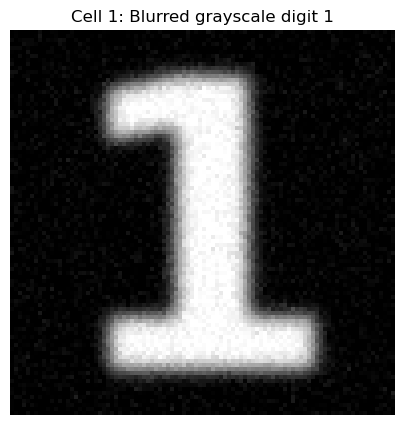

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from matplotlib.font_manager import findfont, FontProperties
from scipy.ndimage import gaussian_filter, binary_closing, binary_fill_holes, label

# 生成 96×96 的灰度数字 1，并人为添加模糊与噪声
N, scale = 96, 4
canvas = Image.new('L', (N * scale, N * scale), 0)
draw = ImageDraw.Draw(canvas)
font = ImageFont.truetype(findfont(FontProperties(family='DejaVu Sans', weight='bold')), size=100 * scale)
bbox = draw.textbbox((0, 0), '1', font=font)
x = (N * scale - (bbox[2] - bbox[0])) // 2 - bbox[0]
y = (N * scale - (bbox[3] - bbox[1])) // 2 - bbox[1]
draw.text((x, y), '1', font=font, fill=255)
clean = np.asarray(canvas.resize((N, N), Image.Resampling.LANCZOS), dtype=float) / 255.0
rng = np.random.default_rng(7)
input_img = np.clip(gaussian_filter(clean, sigma=2.2) + rng.normal(0, 0.035, clean.shape), 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(input_img, cmap='gray', vmin=0, vmax=1)
plt.title('Cell 1: Blurred grayscale digit 1')
plt.axis('off')
plt.show()

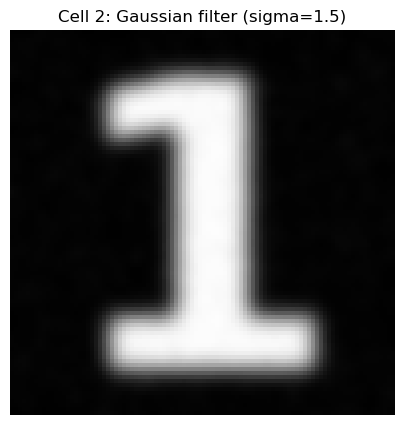

In [2]:
# 高斯滤波：对模糊的数字 1 进一步平滑，减弱随机噪声
sigma_narrow = 1.5  # 单位：像素
gaussian_img = gaussian_filter(input_img, sigma=sigma_narrow)

plt.figure(figsize=(5, 5))
plt.imshow(gaussian_img, cmap='gray', vmin=0, vmax=1)
plt.title(f'Cell 2: Gaussian filter (sigma={sigma_narrow})')
plt.axis('off')
plt.show()

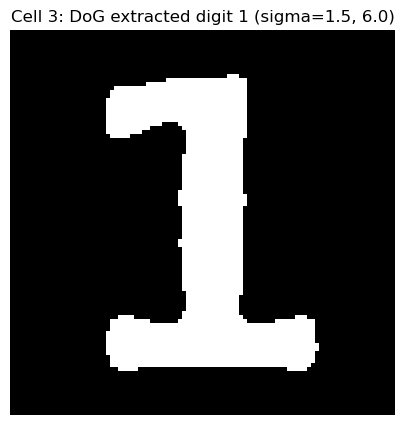

In [3]:
# 差分高斯：窄核结果 - 宽核结果，再用阈值提取数字 1
sigma_broad = 6.0  # 宽核必须大于窄核
broad_img = gaussian_filter(input_img, sigma=sigma_broad)
dog = gaussian_img - broad_img
threshold_rel = 0.20  # 相对 DoG 最大值的阈值
mask = dog > threshold_rel * dog.max()
mask = binary_closing(mask, structure=np.ones((3, 3), dtype=bool))
regions, n_regions = label(mask)
if n_regions > 0:
    sizes = np.bincount(regions.ravel())
    sizes[0] = 0
    mask = regions == sizes.argmax()  # 保留最大连通区域，去掉噪声孤岛
mask = binary_fill_holes(mask)

plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
plt.title(f'Cell 3: DoG extracted digit 1 (sigma={sigma_narrow}, {sigma_broad})')
plt.axis('off')
plt.show()